In [5]:
from pathlib import Path
from utils2 import *
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from task1.utils import *

cells_dir = Path.cwd().resolve().parent / "Data" / "cells"
masks_dir = Path.cwd().resolve().parent / "Data" / "masks_pts"

pairs = []

for img_path in sorted(cells_dir.iterdir()):
    mask_name = img_path.name.replace('cell', 'mask_pts')
    mask_path = masks_dir / mask_name
    
    if mask_path.exists():
        pairs.append((str(img_path), str(mask_path)))

print(f"Found pairs of image-mask: {len(pairs)}, first pair: {pairs[0]}")

Found pairs of image-mask: 352, first pair: ('C:\\Users\\galem\\Documents\\FIT-CTU\\ANI-PIV\\Data\\cells\\cell_0_0.png', 'C:\\Users\\galem\\Documents\\FIT-CTU\\ANI-PIV\\Data\\masks_pts\\mask_pts_0_0.png')


In [18]:
split_idx = int(len(pairs) * 0.8)
batch_size = 8
train_dataset = CiliaDataset(pairs[:split_idx], img_size=256, augment=True)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = CiliaDataset(pairs[split_idx:], img_size=256, augment=False)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
device = torch.accelerator.current_accelerator(
).type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [19]:
model = UNet().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 10

# Use one fixed training sample to compare its image, target mask, and prediction.
preview_img, preview_mask = train_dataset[0]
epoch_outs = []
history = []

In [ ]:
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for imgs, masks in train_dataloader:
        imgs = imgs.to(device)
        masks = masks.to(device)
        # Zero out the gradients
        optimizer.zero_grad()
        # Forward pass, returns logits
        outputs = model(imgs)
        loss = loss_fn(outputs, masks)
        # Backward pass
        loss.backward()
        # Update weights
        optimizer.step()
        # convert tensor to scalar
        train_loss += loss.item()

    model.eval()
    val_loss, val_dice = 0.0, 0.0
    val_acc, val_prec, val_rec, val_f1 = 0.0, 0.0, 0.0, 0.0
    
    with torch.no_grad():
        for imgs, masks in val_dataloader:
            imgs, masks = imgs.to(device), masks.to(device)
            # Get predictions from the model, returns logits    
            outputs = model(imgs)
            val_loss += loss_fn(outputs, masks).item()
            val_dice += dice_coeff(outputs, masks)
            
            acc, prec, rec, f1 = calculate_metrics(
                outputs, masks)
            val_acc += acc
            val_prec += prec
            val_rec += rec
            val_f1 += f1

        preview_logits = model(preview_img.unsqueeze(0).to(device))
        preview_pred = (torch.sigmoid(preview_logits) > 0.5).float()

    pred_show = preview_pred[0].cpu().numpy().squeeze()
    epoch_outs.append(pred_show)

    num_batches = len(val_dataloader)
    
    epoch_metrics = {
        'epoch': epoch + 1,
        'train_loss': train_loss / len(train_dataloader),
        'val_loss': val_loss / num_batches,
        'val_dice': val_dice / num_batches,
        'val_acc': val_acc / num_batches,
        'val_prec': val_prec / num_batches,
        'val_rec': val_rec / num_batches,
        'val_f1': val_f1 / num_batches
    }

    history.append(epoch_metrics)

    print(f"Epoch [{epoch_metrics['epoch']}] | "
          f"Train Loss: {epoch_metrics['train_loss']:.4f} | "
          f"Val Loss: {epoch_metrics['val_loss']:.4f} | "
          f"Dice: {epoch_metrics['val_dice']:.4f} | "
          f"Acc: {epoch_metrics['val_acc']:.4f} | "
          f"Prec: {epoch_metrics['val_prec']:.4f} | "
          f"Rec: {epoch_metrics['val_rec']:.4f} | " 
          f"F1: {epoch_metrics['val_f1']:.4f} | ")

Epoch [1] | Train Loss: 0.3367 | Val Loss: 0.2968 | Dice: 0.0000 | Acc: 0.9373 | Prec: 0.0000 | Rec: 0.0000 | F1: 0.0000 | 
Epoch [2] | Train Loss: 0.2161 | Val Loss: 0.1790 | Dice: 0.8118 | Acc: 0.9746 | Prec: 0.7550 | Rec: 0.8921 | F1: 0.8151 | 
Epoch [3] | Train Loss: 0.1567 | Val Loss: 0.1433 | Dice: 0.7646 | Acc: 0.9715 | Prec: 0.7775 | Rec: 0.7669 | F1: 0.7706 | 
Epoch [4] | Train Loss: 0.1248 | Val Loss: 0.1151 | Dice: 0.7684 | Acc: 0.9701 | Prec: 0.7394 | Rec: 0.8133 | F1: 0.7732 | 
Epoch [5] | Train Loss: 0.1050 | Val Loss: 0.0898 | Dice: 0.7950 | Acc: 0.9764 | Prec: 0.8411 | Rec: 0.7684 | F1: 0.8021 | 
Epoch [6] | Train Loss: 0.0926 | Val Loss: 0.0834 | Dice: 0.8164 | Acc: 0.9748 | Prec: 0.7499 | Rec: 0.9056 | F1: 0.8186 | 


In [ ]:
# epoch_outs = epoch_outs[-num_epochs:]
# if len(history) > num_epochs:
#     history = history[-num_epochs:]

10


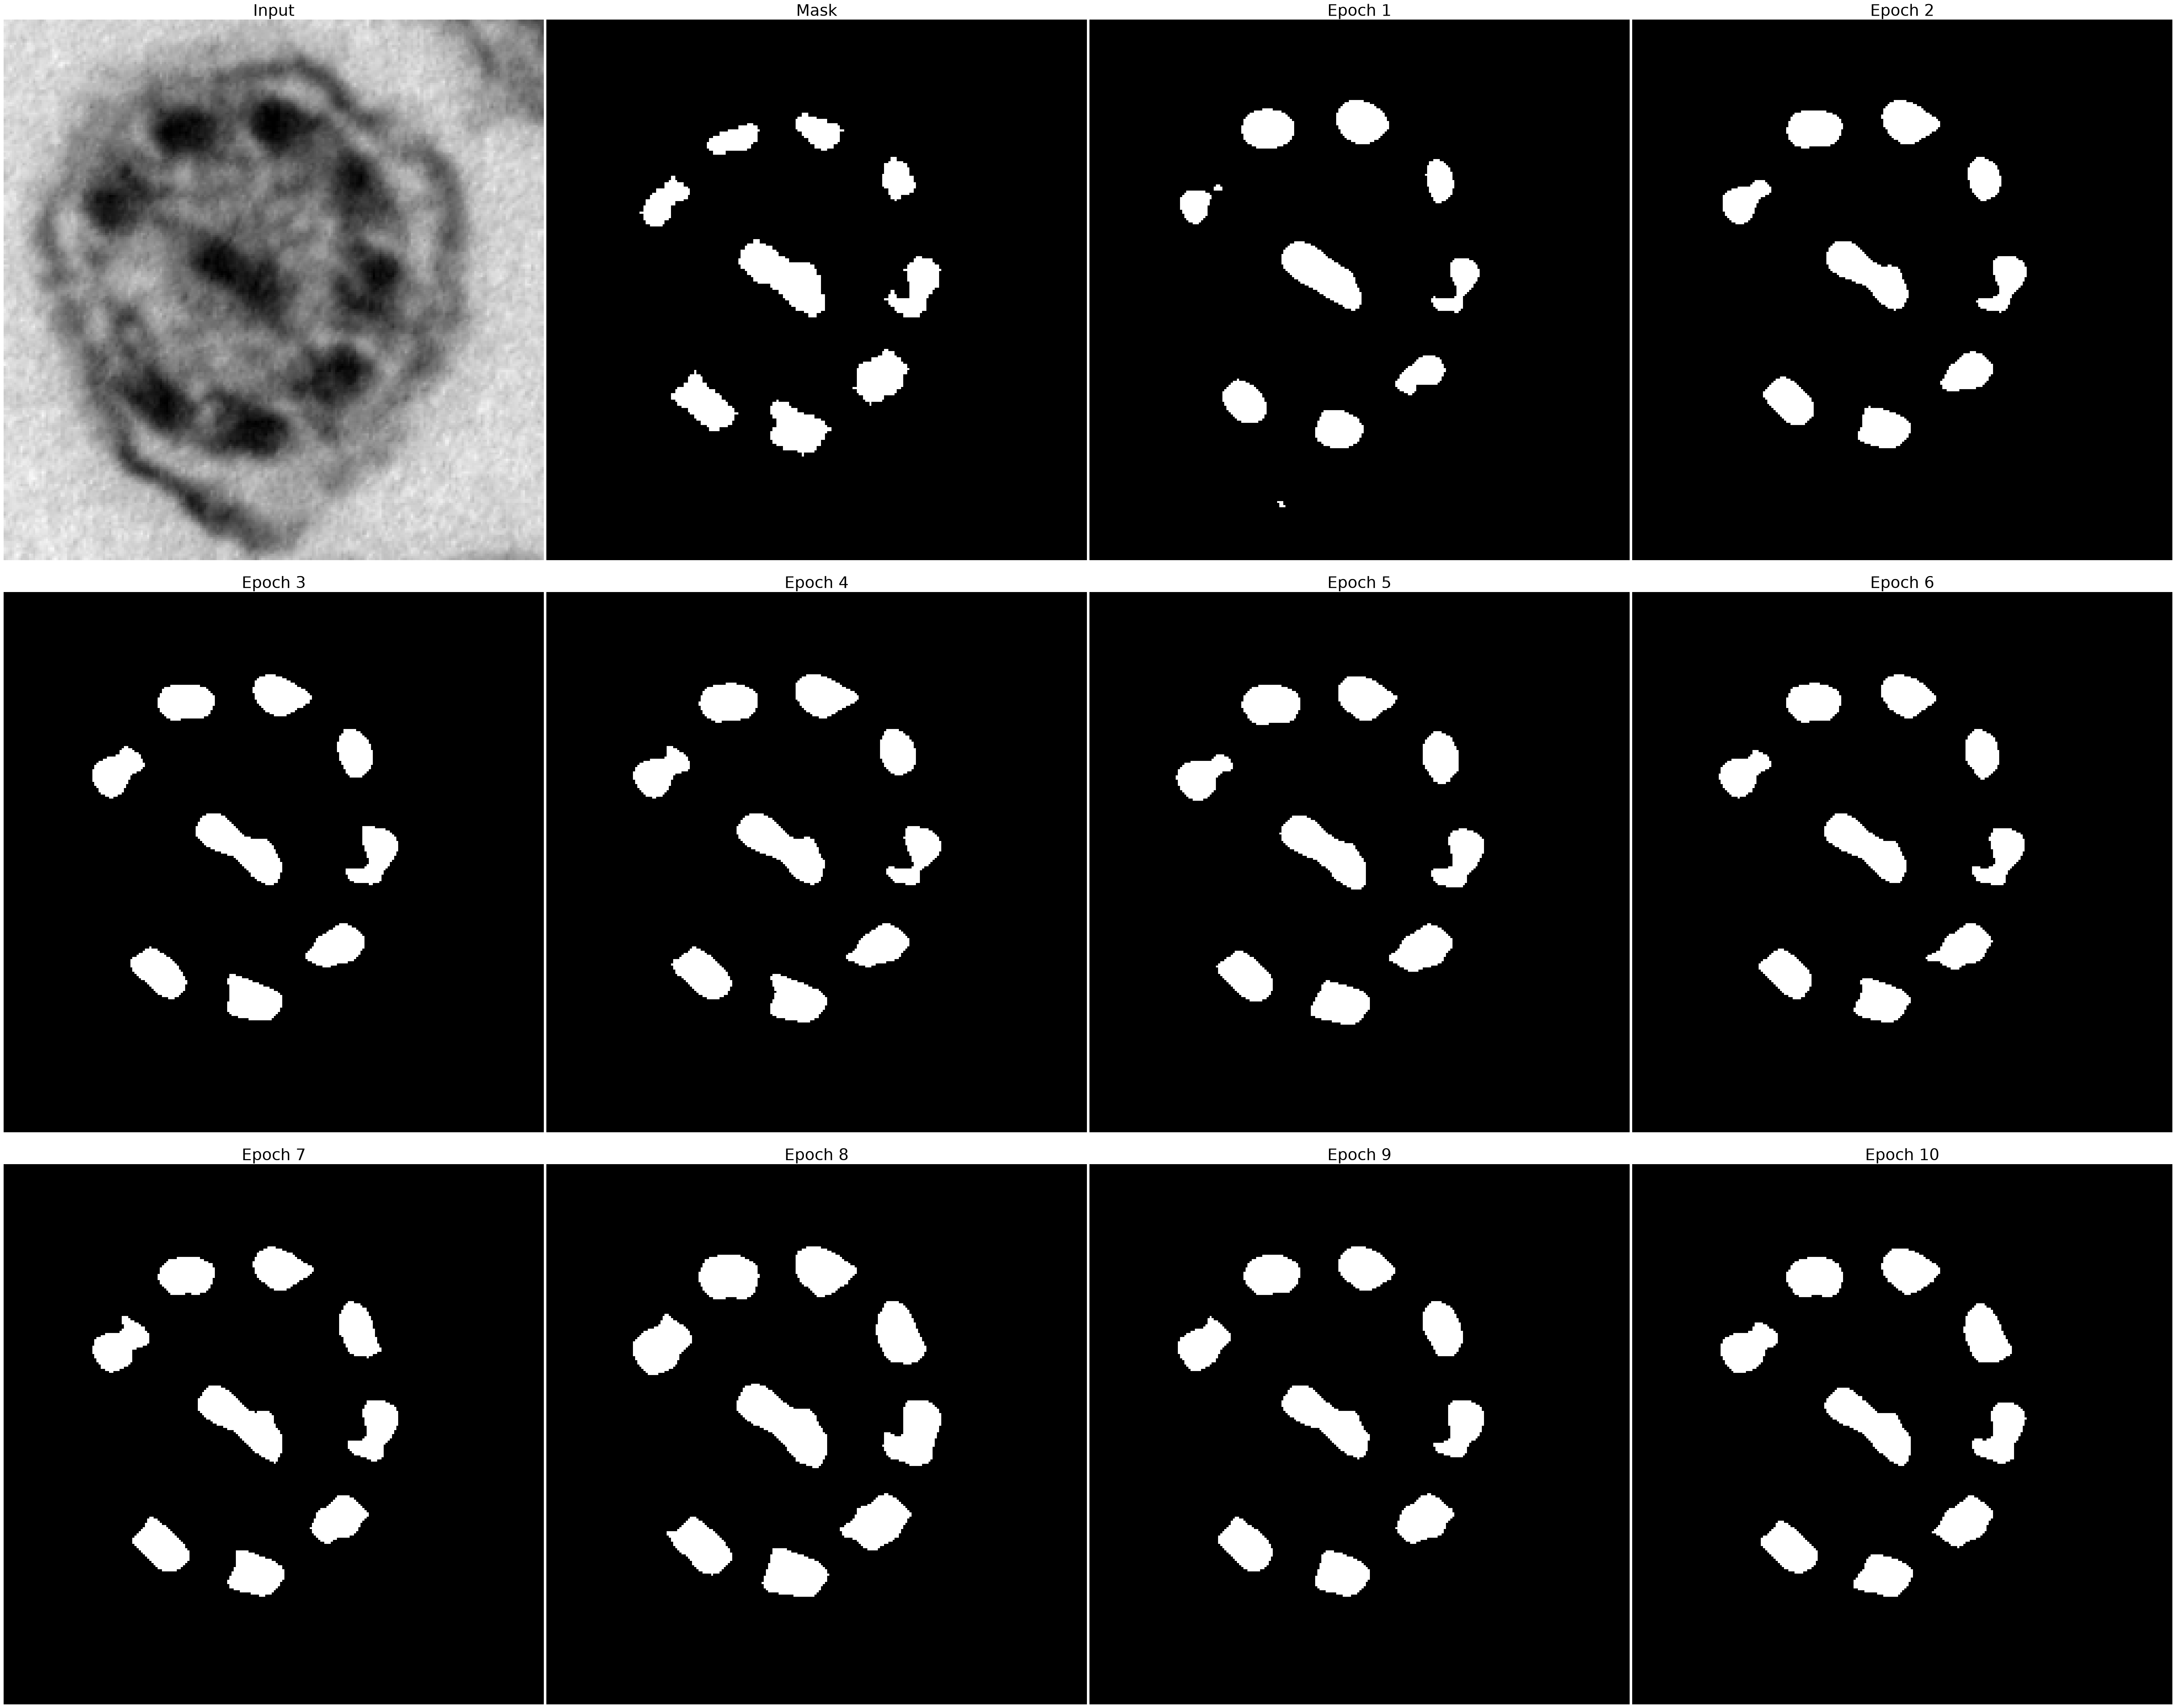

In [14]:
img_show = preview_img.cpu().numpy().squeeze()
mask_show = preview_mask.cpu().numpy().squeeze()
titles = ["Input", "Mask"]
for i in range(num_epochs):
    titles.append(f"Epoch {i+1}")
print(len(epoch_outs))
plot_images(img_show, mask_show, *epoch_outs, titles=titles)

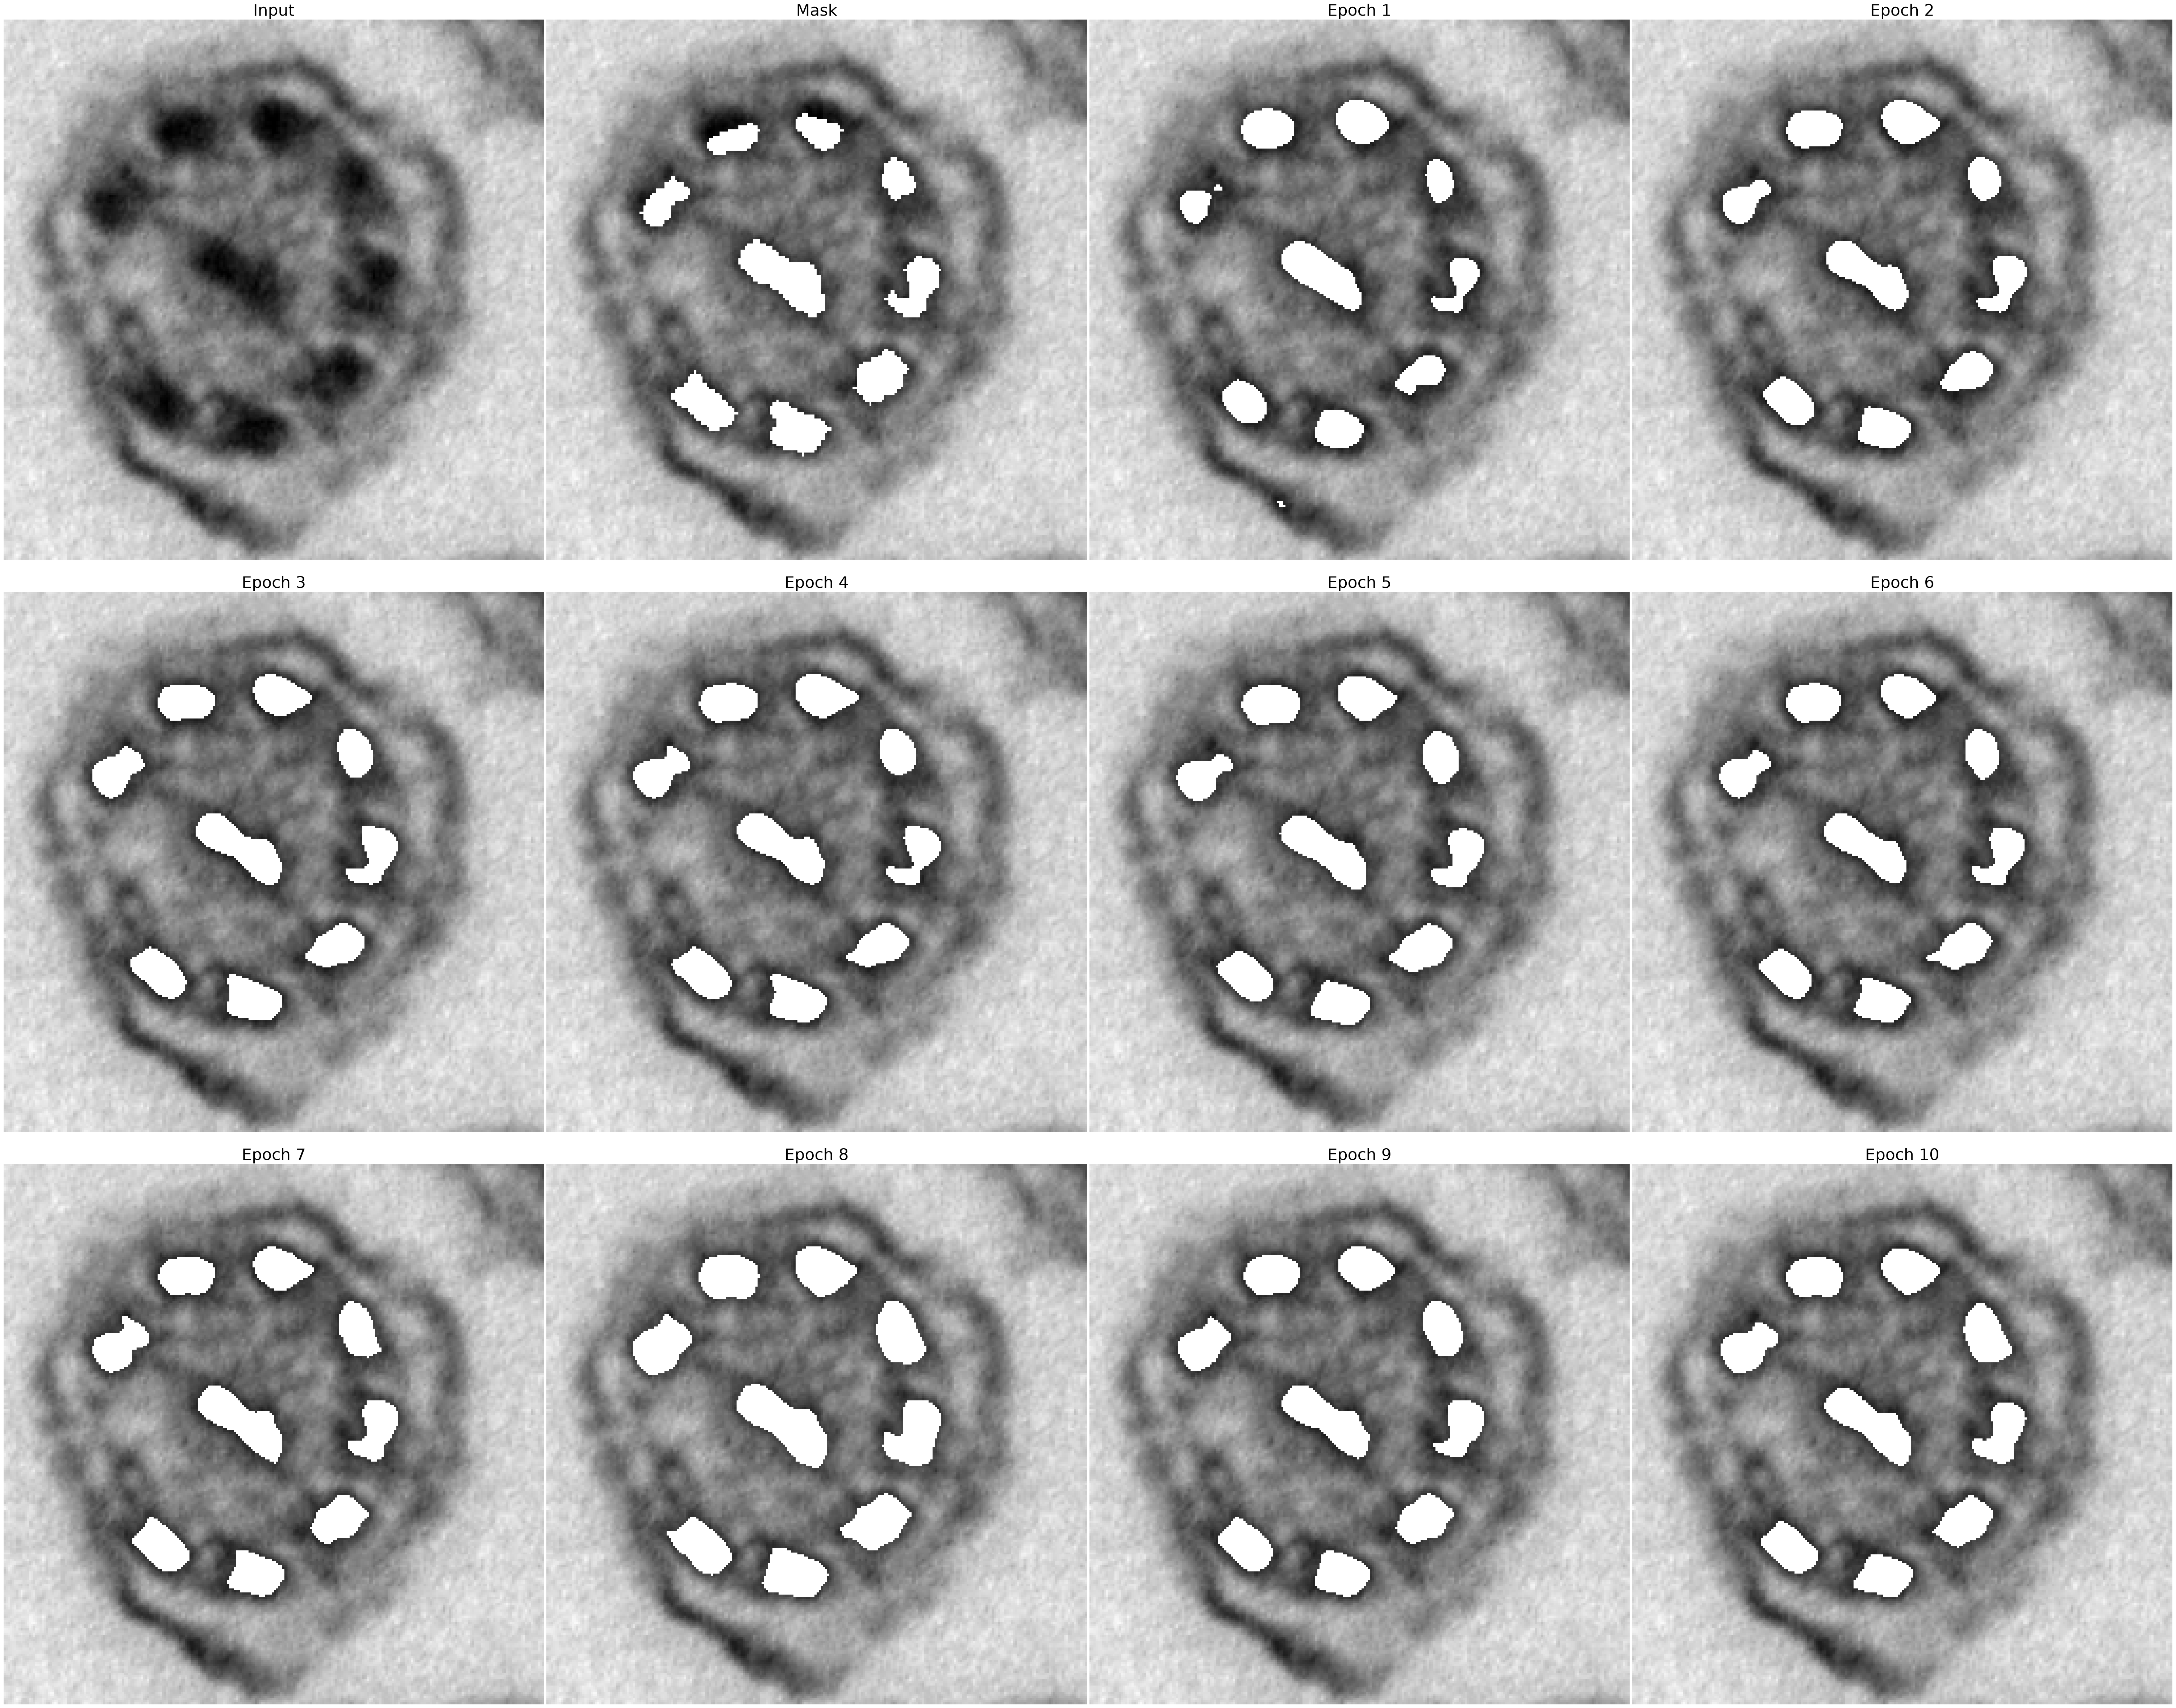

In [15]:
masked_true = cv.bitwise_or(img_show, mask_show)
len(titles)
masked_epoch = [cv.bitwise_or(img_show, e) for e in epoch_outs]
plot_images(img_show, masked_true, *masked_epoch, titles=titles)

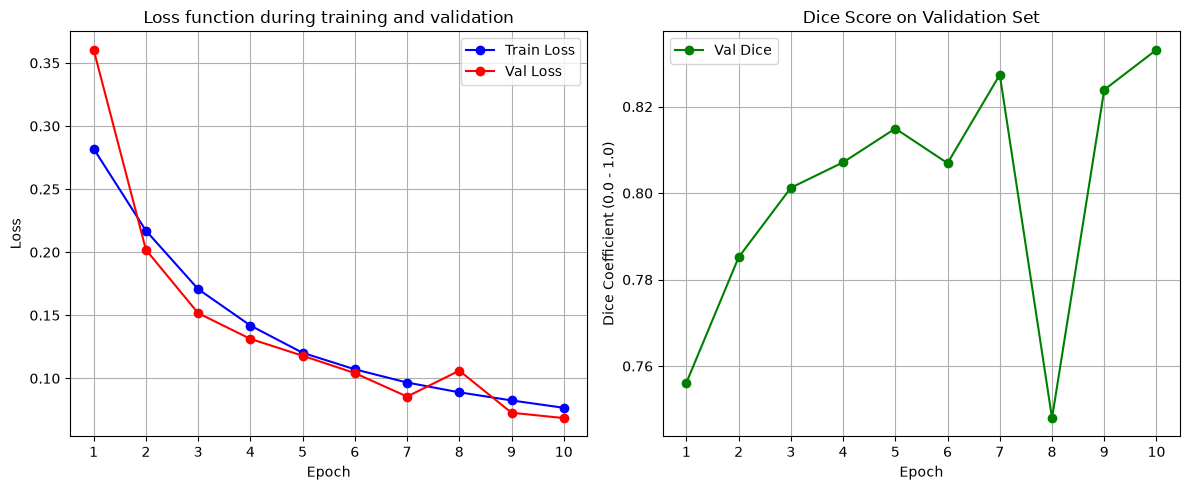

In [16]:
epochs = list(range(1, len(history) + 1)) if len(history) > 0 else list(range(1, num_epochs + 1))

def get_metric(key):
    if isinstance(history, dict):
        return history[key]
    return [h[key] for h in history]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, get_metric('train_loss'), label='Train Loss', color='blue', marker='o')
plt.plot(epochs, get_metric('val_loss'), label='Val Loss', color='red', marker='o')
plt.title('Loss function during training and validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, get_metric('val_dice'), label='Val Dice', color='green', marker='o')
plt.title('Dice Score on Validation Set')
plt.xlabel('Epoch')
plt.ylabel('Dice Coefficient (0.0 - 1.0)')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Průběh dalších validačních metrik (Accuracy, Precision, Recall, F1-Score)
Grafy níže znázorňují vývoj dodatečných metrik vyhodnocovaných na validační sadě v průběhu trénování:
- **Accuracy**: Celková správnost klasifikace jednotlivých pixelů ($(TP + TN) / (TP + TN + FP + FN)$).
- **Precision**: Přesnost detekce – poměr skutečných cilia pixelů ku všem detekovaným pixelům ($TP / (TP + FP)$).
- **Recall**: Úplnost / Senzitivita – schopnost modelu zachytit všechny skutečné pixely řasinek ($TP / (TP + FN)$).
- **F1-Score**: Harmonický průměr mezi Precision a Recall ($2 \cdot \frac{P \cdot R}{P + R}$).

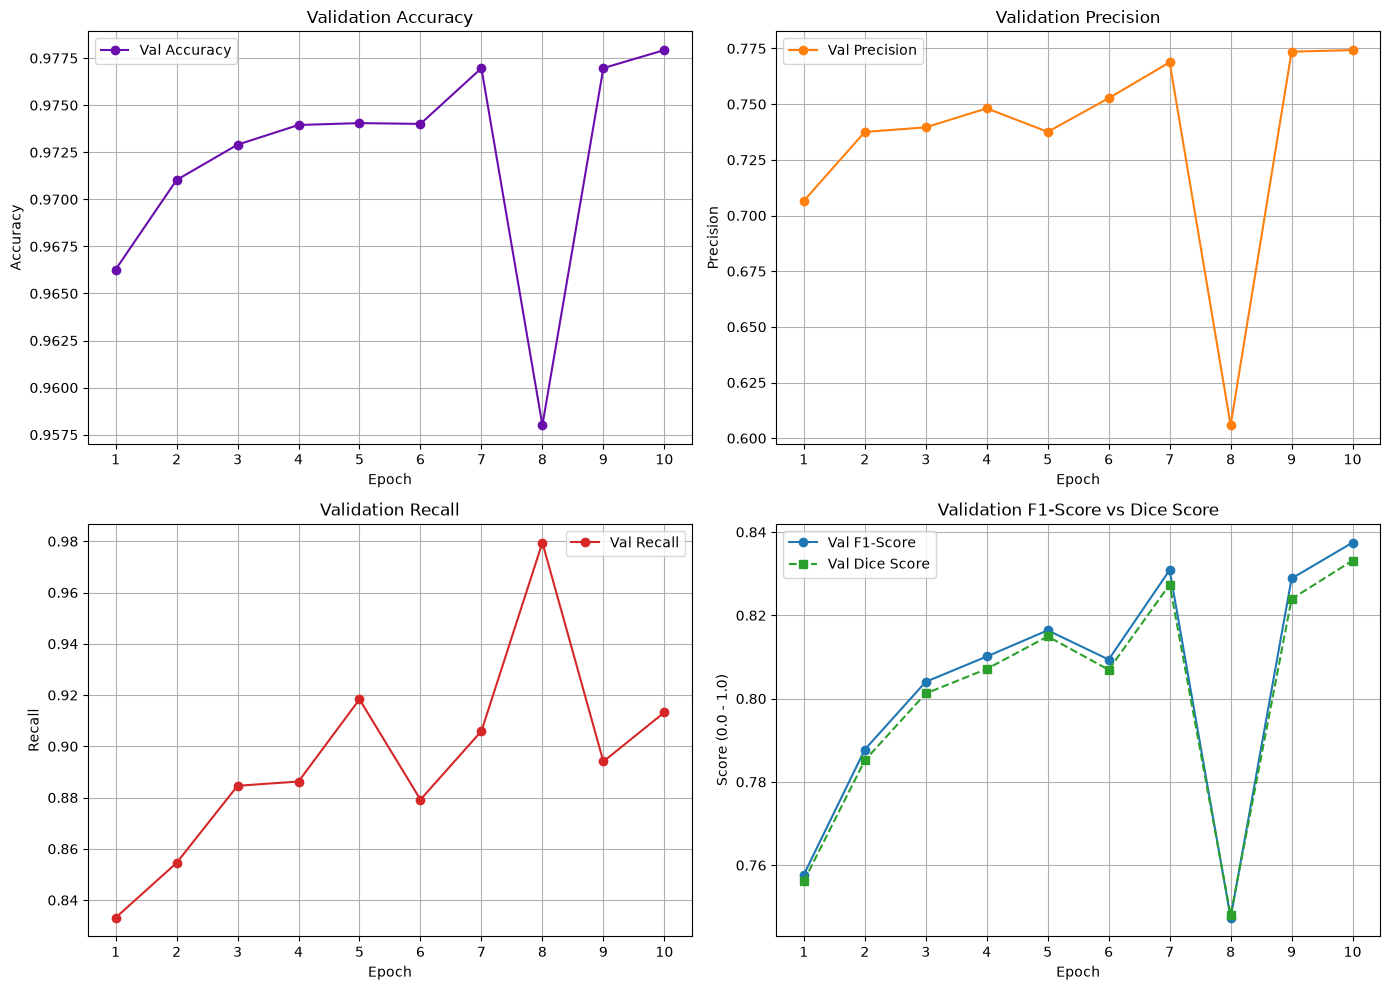

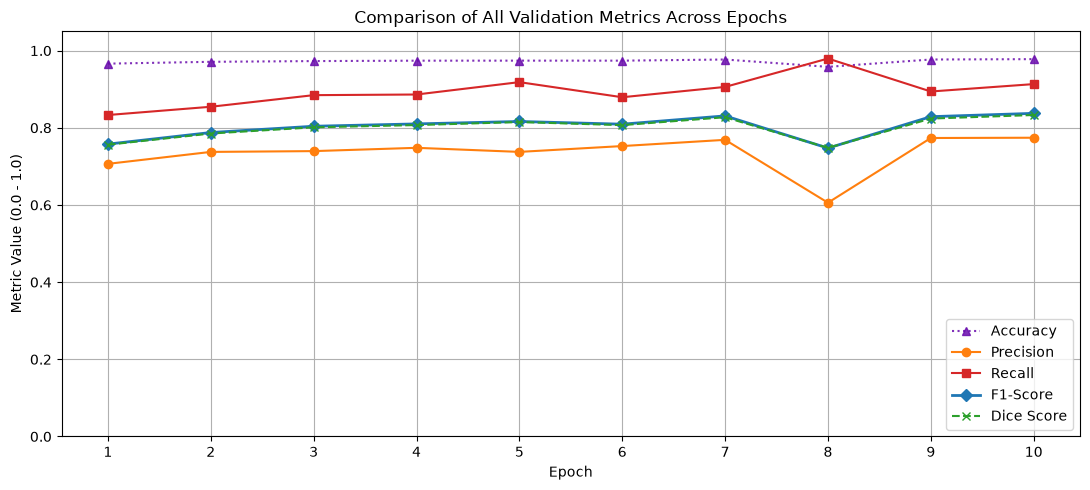

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy
axes[0, 0].plot(epochs, get_metric('val_acc'), label='Val Accuracy', color='#6A0DAD', marker='o')
axes[0, 0].set_title('Validation Accuracy')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].set_xticks(epochs)
axes[0, 0].legend()
axes[0, 0].grid(True)

# Precision
axes[0, 1].plot(epochs, get_metric('val_prec'), label='Val Precision', color='#FF7F0E', marker='o')
axes[0, 1].set_title('Validation Precision')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Precision')
axes[0, 1].set_xticks(epochs)
axes[0, 1].legend()
axes[0, 1].grid(True)

# Recall
axes[1, 0].plot(epochs, get_metric('val_rec'), label='Val Recall', color='#D62728', marker='o')
axes[1, 0].set_title('Validation Recall')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Recall')
axes[1, 0].set_xticks(epochs)
axes[1, 0].legend()
axes[1, 0].grid(True)

# F1-Score vs Dice Score
axes[1, 1].plot(epochs, get_metric('val_f1'), label='Val F1-Score', color='#1F77B4', marker='o')
axes[1, 1].plot(epochs, get_metric('val_dice'), label='Val Dice Score', color='#2CA02C', marker='s', linestyle='--')
axes[1, 1].set_title('Validation F1-Score vs Dice Score')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Score (0.0 - 1.0)')
axes[1, 1].set_xticks(epochs)
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(epochs, get_metric('val_acc'), label='Accuracy', color='#6A0DAD', marker='^', linestyle=':', alpha=0.85)
plt.plot(epochs, get_metric('val_prec'), label='Precision', color='#FF7F0E', marker='o')
plt.plot(epochs, get_metric('val_rec'), label='Recall', color='#D62728', marker='s')
plt.plot(epochs, get_metric('val_f1'), label='F1-Score', color='#1F77B4', marker='D', linewidth=2)
plt.plot(epochs, get_metric('val_dice'), label='Dice Score', color='#2CA02C', marker='x', linestyle='--')
plt.title('Comparison of All Validation Metrics Across Epochs')
plt.xlabel('Epoch')
plt.ylabel('Metric Value (0.0 - 1.0)')
plt.xticks(epochs)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()